# 3. Model evaluation

Reads what the evaluation scripts wrote. Run these first, from `backend/`:

```
python -m training.evaluate
python -m training.baseline
python -m training.error_analysis
```

In [1]:
import sys
from pathlib import Path

# Make `app` and `training` importable from the notebooks folder.
BACKEND = Path.cwd().resolve().parent / "backend" if Path.cwd().name == "notebooks" else Path.cwd() / "backend"
sys.path.insert(0, str(BACKEND))

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)

In [2]:
import json
from app.paths import DOCS_DIR, MODELS_DIR

report = json.loads((MODELS_DIR / "evaluation_report.json").read_text(encoding="utf-8"))
print("generated:", report["generated_at"], "| test domains:", report["domains"])
pd.DataFrame({name: {
    "domains": ", ".join(log["hyperparameters"]["domains"]),
    "epochs": log["hyperparameters"]["epochs"],
    "best epoch": log["best_epoch"],
    "validation score": round(log["best_validation_score"], 4),
    "minutes": log["training_minutes"],
} for name, log in report["training"].items()})

generated: 2026-10-10T05:00:39+00:00 | test domains: ['laptops', 'restaurants']


,aspect,sentiment,overall
domains,"laptops, restaurants","laptops, restaurants","laptops, restaurants"
epochs,3,4,4
best epoch,3,3,4
validation score,0.8312,0.7574,0.7363
minutes,78.62,94.96,37.33


## Headline metrics per test domain

,all,laptops,restaurants
aspect F1,0.8462,0.8021,0.8715
sentiment accuracy,0.8151,0.7743,0.8384
sentiment macro-F1,0.7456,0.7322,0.7528
mixed-sentence accuracy,0.6616,0.5728,0.7018
overall macro-F1,0.7202,0.7310,0.7074
end-to-end F1,0.6977,0.6308,0.7355


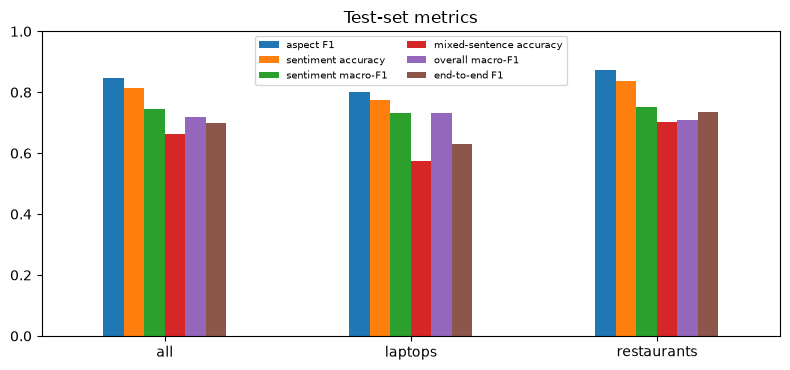

In [3]:
def headline(results):
    return {
        "aspect F1": results["aspect_extraction"]["f1"],
        "sentiment accuracy": results["aspect_sentiment"]["accuracy"],
        "sentiment macro-F1": results["aspect_sentiment"]["macro"]["f1"],
        "mixed-sentence accuracy": results["aspect_sentiment_by_sentence_type"]["mixed"]["accuracy"],
        "overall macro-F1": results["overall_sentiment"]["macro"]["f1"],
        "end-to-end F1": results["end_to_end"]["f1"],
    }

metrics = pd.DataFrame({scope: headline(r) for scope, r in report["results"].items()}).round(4)
display(metrics)
metrics.T.plot(kind="bar", figsize=(8, 3.8), rot=0, ylim=(0, 1), title="Test-set metrics")
plt.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

## Per-class results and confusion matrix (aspect sentiment)

Neutral is the hardest class.

In [4]:
sentiment = report["results"]["all"]["aspect_sentiment"]
display(pd.DataFrame(sentiment["per_class"]).T.round(4))
confusion = sentiment["confusion_matrix"]
pd.DataFrame(confusion["matrix"], index=[f"true {l}" for l in confusion["labels"]],
             columns=[f"pred {l}" for l in confusion["labels"]])

,precision,recall,f1,support
negative,0.6651,0.8580,0.7493,324.0
neutral,0.6973,0.4986,0.5815,365.0
positive,0.9018,0.9102,0.9060,1069.0


,pred negative,pred neutral,pred positive
true negative,278,28,18
true neutral,95,182,88
true positive,45,51,973


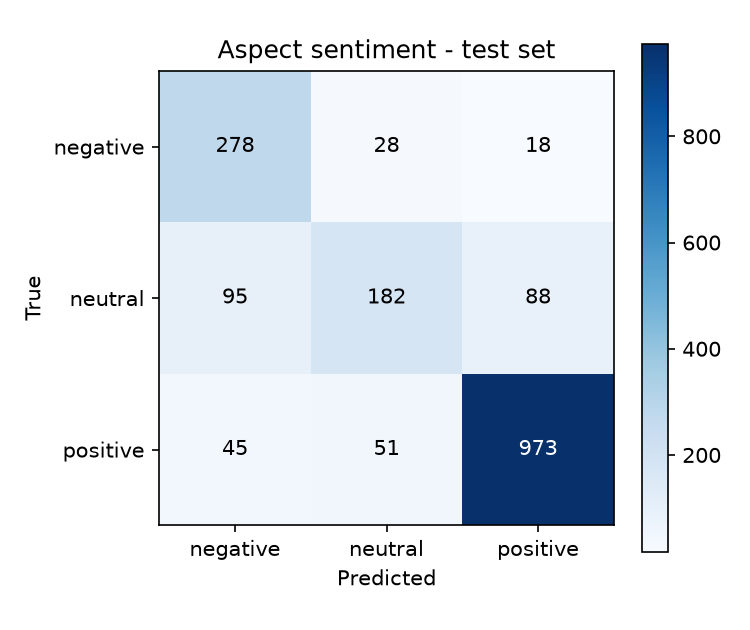

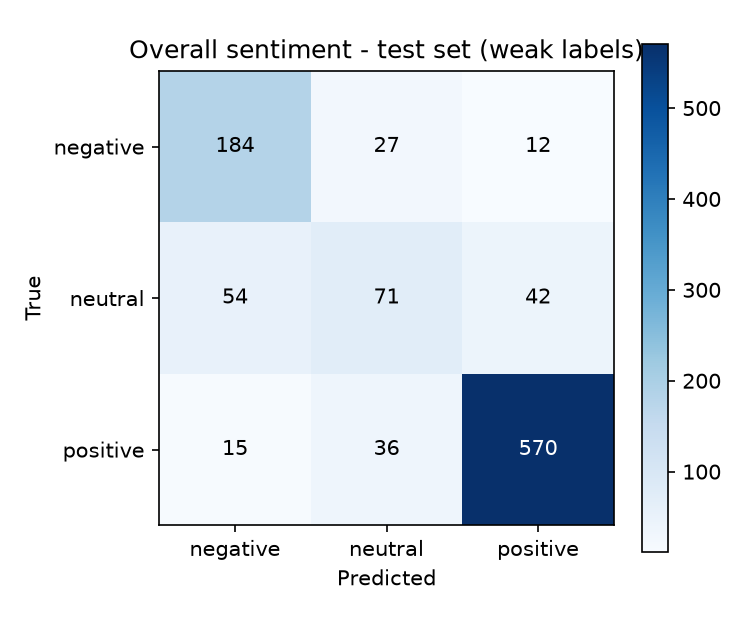

In [5]:
from IPython.display import Image, display as show
for name in ("sentiment_confusion_matrix.png", "overall_confusion_matrix.png"):
    show(Image(filename=str(DOCS_DIR / "figures" / name), width=420))

## What BERT adds over a rule-and-lexicon baseline

,baseline,BERT,difference
aspect F1,0.3765,0.8462,0.4697
sentiment macro-F1,0.6159,0.7456,0.1297
overall macro-F1,0.6475,0.7202,0.0727
end-to-end F1,0.2530,0.6977,0.4447


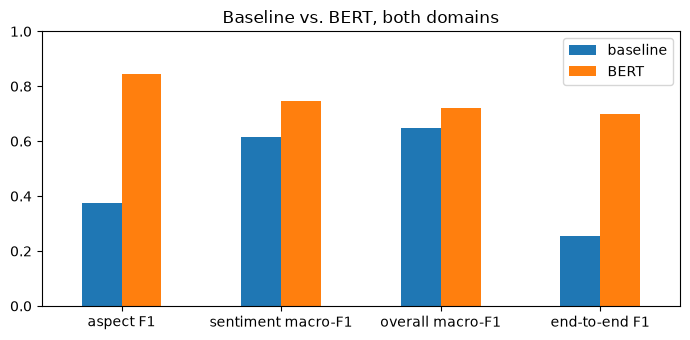

In [6]:
baseline = json.loads((MODELS_DIR / "baseline_report.json").read_text(encoding="utf-8"))
paths = {"aspect F1": ("aspect_extraction", "f1"), "sentiment macro-F1": ("aspect_sentiment", "macro", "f1"),
         "overall macro-F1": ("overall_sentiment", "macro", "f1"), "end-to-end F1": ("end_to_end", "f1")}

def pick(results, path):
    for key in path:
        results = results[key]
    return results

comparison = pd.DataFrame({
    "baseline": {n: pick(baseline["results"]["all"], p) for n, p in paths.items()},
    "BERT": {n: pick(report["results"]["all"], p) for n, p in paths.items()},
}).round(4)
comparison["difference"] = (comparison.BERT - comparison.baseline).round(4)
display(comparison)
comparison[["baseline", "BERT"]].plot(kind="bar", figsize=(7, 3.5), rot=0, ylim=(0, 1), title="Baseline vs. BERT, both domains")
plt.tight_layout(); plt.show()

## Error analysis and transfer

The full tables are in `docs/error_analysis.md` and `docs/transfer.md`.

In [7]:
from IPython.display import Markdown
for name in ("error_analysis.md", "transfer.md"):
    path = DOCS_DIR / name
    text = path.read_text(encoding="utf-8") if path.exists() else f"`{name}` not found: run `python -m training.error_analysis`."
    show(Markdown(text))

# Error analysis

> Generated by `python -m training.error_analysis`. Do not edit by hand.

- Generated: 2026-10-10T05:02:57+00:00
- Models: the deployed models; data: SemEval-2014 Task 4 gold test set.
- Headline metrics are in [results.md](results.md); this file looks at the errors behind them.

## Domain: laptops

### Aspect extraction

| Outcome | Aspects | Share of gold aspects |
|---|---|---|
| Found with exact boundaries | 535 | 81.8% |
| Found with wrong boundaries | 62 | 9.5% |
| Missed entirely | 57 | 8.7% |

Predictions that match no gold aspect (spurious): 51.

| Aspect length | Gold aspects | Found exactly |
|---|---|---|
| one word | 362 | 89.5% |
| several words | 292 | 72.3% |

Aspect terms most often missed or cut short:

- starts up (2)
- aluminum (2)
- graphic design (2)
- working (2)
- function (2)
- slot (2)
- installation disk ( dvd ) (1)
- works (1)
- mountain lion (1)
- configure (1)
- portable computing (1)
- ms office 2011 for mac (1)
- look (1)
- lit up keys (1)
- squaretrade 3 - year computer accidental protection warranty (1)

### Aspect sentiment (gold aspects given)

144 of 638 aspects are misclassified (22.6%).

| Gold sentiment | Predicted as | Errors | Share of all errors |
|---|---|---|---|
| neutral | negative | 58 | 40.3% |
| positive | negative | 26 | 18.1% |
| positive | neutral | 26 | 18.1% |
| neutral | positive | 26 | 18.1% |
| negative | neutral | 5 | 3.5% |
| negative | positive | 3 | 2.1% |

Accuracy by the confidence the model reports. If confidence carries
information, accuracy rises from the first row to the last:

| Confidence | Predictions | Accuracy |
|---|---|---|
| below 0.60 | 37 | 43.2% |
| 0.60 to 0.80 | 90 | 53.3% |
| 0.80 and above | 511 | 84.1% |

A random sample of misclassified aspects (seed fixed, at most 20):

| Sentence | Aspect | Gold | Predicted | Confidence |
|---|---|---|---|---|
| I needed a laptop with big storage, a nice screen and fast so I can photoshop without any problem. | storage | neutral | positive | 95% |
| A veryimportant feature is Firewire 800 which in my experience works better then USB3 (in PC enabled with USB3)I was not originally sold on the MAC OS I felt it was inferior in many ways To Windows 7. | Firewire 800 | positive | negative | 73% |
| I switched to this because I wanted something different, even though I miss windows. | windows | positive | negative | 55% |
| The Mac mini is about 8x smaller than my old computer which is a huge bonus and runs very quiet, actually the fans aren't audible unlike my old pc | fans | positive | negative | 88% |
| 12.44 seconds to boot. | boot | neutral | positive | 76% |
| I've had it for about 2 months now and found no issues with software or updates. | updates | neutral | positive | 66% |
| WiFi capability, disk drive and multiple USB ports to connect scale and printers was all that was required. | USB ports | positive | neutral | 96% |
| Within a few hours I was using the gestures unconsciously. | gestures | positive | neutral | 51% |
| I had to buy a wireless mouse to go with it, as I am old school and hate the pad, but knew that before I bought it, now it works great, need to get adjusted to the key board, as I am used to a bigger one and pounding. | key board | neutral | negative | 65% |
| And as for all the fancy finger swipes -- I just gave up and attached a mouse. | finger swipes | negative | positive | 83% |
| I was a little worry at first because I don't have a lot of experience with os.x and windows has always been second nature to me after many years of using windows. | windows | neutral | negative | 58% |
| This newer netbook has no hard drive or network lights. | hard drive | neutral | negative | 92% |
| This newer netbook has no hard drive or network lights. | network lights | neutral | negative | 92% |
| I needed a laptop with big storage, a nice screen and fast so I can photoshop without any problem. | screen | neutral | positive | 100% |
| So happy with this purchase, I just wish it came with Microsoft Word. | Microsoft Word | neutral | negative | 73% |
| It shouldn't happen like that, I don't have any design app open or anything. | design app | neutral | negative | 77% |
| I know some people complained about HDMI issues but they released a firmware patch to address that issue. | HDMI | neutral | negative | 85% |
| I like the Mini Mac it was easy to setup and install, but I am learning as I go and could use a tutorial to learn how to use some of the features I was use to on the PC especially the right mouse click menu. | tutorial | neutral | positive | 61% |
| Fan only comes on when you are playing a game. | Fan | neutral | negative | 73% |
| After fumbling around with the OS I started searching the internet for a fix and found a number of forums on fixing the issue. | OS | negative | neutral | 50% |

## Domain: restaurants

### Aspect extraction

| Outcome | Aspects | Share of gold aspects |
|---|---|---|
| Found with exact boundaries | 1017 | 89.7% |
| Found with wrong boundaries | 78 | 6.9% |
| Missed entirely | 39 | 3.4% |

Predictions that match no gold aspect (spurious): 74.

| Aspect length | Gold aspects | Found exactly |
|---|---|---|
| one word | 812 | 94.8% |
| several words | 322 | 76.7% |

Aspect terms most often missed or cut short:

- place (6)
- waiting (3)
- dining experience (3)
- flavor (2)
- lychee martini (1)
- portions of the food (1)
- waitress ' s (1)
- tart of the day (1)
- portion size (1)
- portobello / gorgonzola / sausage appetizer (1)
- lemon - dressed cobb (1)
- hot dog (1)
- creme brulee (1)
- chili signed food items (1)
- beef (1)

### Aspect sentiment (gold aspects given)

181 of 1120 aspects are misclassified (16.2%).

| Gold sentiment | Predicted as | Errors | Share of all errors |
|---|---|---|---|
| neutral | positive | 62 | 34.3% |
| neutral | negative | 37 | 20.4% |
| positive | neutral | 25 | 13.8% |
| negative | neutral | 23 | 12.7% |
| positive | negative | 19 | 10.5% |
| negative | positive | 15 | 8.3% |

Accuracy by the confidence the model reports. If confidence carries
information, accuracy rises from the first row to the last:

| Confidence | Predictions | Accuracy |
|---|---|---|
| below 0.60 | 72 | 50.0% |
| 0.60 to 0.80 | 124 | 46.8% |
| 0.80 and above | 924 | 91.5% |

A random sample of misclassified aspects (seed fixed, at most 20):

| Sentence | Aspect | Gold | Predicted | Confidence |
|---|---|---|---|---|
| don't get me wrong - sushi was good, just not fantastic. | sushi | positive | neutral | 63% |
| How can hope to stay in business with service like this? | service | negative | positive | 47% |
| Service is known for bending over backwards to make everyone happy. | Service | positive | negative | 60% |
| I HAVE NEVER HAD A BAD MEAL(OR BAD SERVICE )@ PIGALLE. | MEAL | positive | negative | 58% |
| The sushi is cut in blocks bigger than my cell phone. | sushi | negative | neutral | 70% |
| Build a meal with side orders like Amazin' Greens salads, Buffalo Chicken Kickers and Cinna Stix. | meal | neutral | positive | 58% |
| i have eaten here on a different occasion - the food is mediocre for the prices. | prices | negative | positive | 85% |
| Thick fries, meaty chili and stuffed baked potatoes round out a menu that includes a cool, ultra-thick chocolate Frosty. | stuffed baked potatoes | neutral | positive | 99% |
| Would you ever believe that when you complain about over an hour wait, when they tell you it will be 20-30 minutes, the manager tells the bartender to spill the drinks you just paid for? | drinks | neutral | negative | 67% |
| There was only one waiter for the whole restaurant upstairs. | waiter | neutral | negative | 67% |
| Average cake thats been courted by a LOT of hype. | cake | negative | positive | 76% |
| The decor is designed in a contemporary Japanese style restaurant. | decor | neutral | positive | 83% |
| No green beans, no egg, no anchovy dressing, no nicoise olives, no red onion. | egg | neutral | negative | 84% |
| How pretentious and inappropriate for MJ Grill to claim that it provides power lunch and dinners! | lunch | negative | positive | 72% |
| No green beans, no egg, no anchovy dressing, no nicoise olives, no red onion. | green beans | neutral | negative | 84% |
| Build a meal with side orders like Amazin' Greens salads, Buffalo Chicken Kickers and Cinna Stix. | Cinna Stix | neutral | positive | 91% |
| The closest that I got was the Cherry Marscapone, but they were out of it that day. | Cherry Marscapone | neutral | negative | 74% |
| The room is a gorgeous, bi-level space and the long bar perfect for a drink. | drink | neutral | positive | 97% |
| " The menu includes pub fare--burgers, steaks and shepherds pie--and even a portabella lasagna for those black sheep known as "vegetarians. | menu | neutral | positive | 58% |
| i have eaten here on a different occasion - the food is mediocre for the prices. | food | neutral | positive | 65% |


# Cross-domain transfer

> Generated by `python -m training.error_analysis`. Do not edit by hand.

- Generated: 2026-10-10T05:02:57+00:00

## Measured: laptop-trained models on restaurant reviews

The first models of this project were trained on laptop reviews only. Evaluating
them on the restaurant test set shows what happens on a product category the
models never saw. The second column is the deployed pair of models, trained on
both domains, on the same sentences.

### Restaurant test set (unseen domain for the laptops-only models)

| Metric | Trained on laptops only | Trained on both domains | Difference |
|---|---|---|---|
| Aspect extraction F1 | 0.3704 | 0.8715 | +0.5011 |
| Aspect sentiment accuracy | 0.7696 | 0.8384 | +0.0687 |
| Aspect sentiment macro-F1 | 0.5524 | 0.7528 | +0.2004 |
| End-to-end F1 | 0.3182 | 0.7355 | +0.4173 |

### Laptop test set (seen by both)

| Metric | Trained on laptops only | Trained on both domains | Difference |
|---|---|---|---|
| Aspect extraction F1 | 0.7900 | 0.8021 | +0.0121 |
| Aspect sentiment accuracy | 0.7069 | 0.7743 | +0.0674 |
| Aspect sentiment macro-F1 | 0.5796 | 0.7322 | +0.1525 |
| End-to-end F1 | 0.5612 | 0.6308 | +0.0696 |

## Illustration: reviews of other product categories

There is no annotated test data for other categories, so this is an illustration,
not a measurement. The reviews in `data/samples/other_domains.csv` were written by
hand; the table shows what the deployed pipeline returns for each. Read the
aspect column and judge: an aspect that a person would not name, or a sentiment
a person would not agree with, is an error.

| Category | Review | Overall | Aspects found |
|---|---|---|---|
| phones | The camera takes sharp photos in daylight, but the battery barely lasts until the evening. | negative | battery (negative, 97%) |
| phones | Call quality is clear and the fingerprint sensor is fast. | positive | Call quality (positive, 100%), fingerprint sensor (positive, 100%) |
| phones | The speaker is tinny and the charger stopped working after a month. | negative | speaker (negative, 98%), charger (negative, 98%) |
| phones | I bought it for my mother and she uses it every day. | neutral | none |
| hotels | The room was spotless and the bed was comfortable, although the wifi kept dropping. | positive | room (negative, 61%), bed (positive, 99%), wifi (negative, 98%) |
| hotels | Breakfast was disappointing and the staff at the reception were rude. | negative | Breakfast (negative, 98%), staff (negative, 98%), reception (negative, 97%) |
| hotels | Great location, a short walk from the station, and the pool is lovely. | positive | location (positive, 100%), pool (positive, 100%) |
| hotels | The air conditioning was noisy, so we hardly slept. | negative | air conditioning (negative, 98%) |
| headphones | The noise cancellation is impressive and the ear cushions are soft. | positive | noise cancellation (positive, 99%), ear cushions (positive, 97%) |
| headphones | Bass is muddy and the bluetooth connection drops every few minutes. | negative | Bass (negative, 98%), bluetooth connection (negative, 98%) |
| headphones | The carrying case feels cheap, but the sound quality is excellent for the price. | positive | carrying case (positive, 97%), sound quality (positive, 95%), price (positive, 90%) |
| headphones | The microphone is fine for calls. | positive | microphone (positive, 96%) |
